In [53]:
import pandas as pd
import matplotlib.pyplot as plt

In [54]:
def plot(file, column, column_label, outfile):
    df = pd.read_csv(file)
    stats = df.groupby("step")[column].agg(["mean", "std"])

    x = stats.index
    mean = stats["mean"]
    std = stats["std"]

    plt.figure()

    plt.plot(x, mean, color="#000", linewidth=1.5)
    #plt.scatter(x, mean, color="#000")
    plt.fill_between(x, mean - std, mean + std, color="#000", alpha=0.1)

    plt.xlabel("Step")
    plt.ylabel(column_label)

    plt.tight_layout()
    plt.savefig(outfile, dpi=300)
    plt.show()

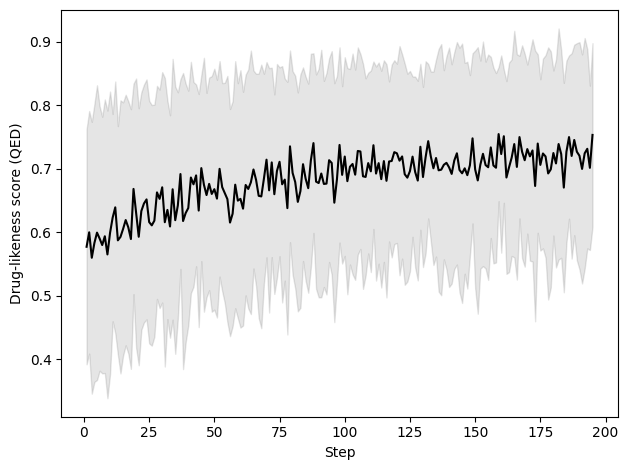

In [55]:
plot("data/staged_learning_1.csv", "Drug-likeness (raw)", "Drug-likeness score (QED)", "results/RL_stage1_QED.png")

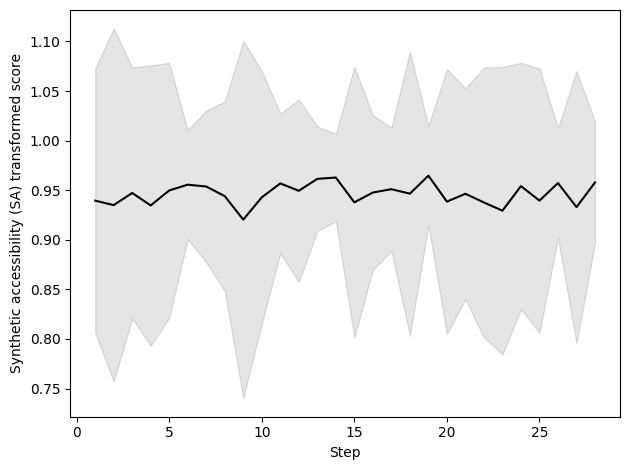

In [56]:
plot("data/staged_learning_2.csv", "SA score", "Synthetic accessibility (SA) transformed score", "results/RL_stage2_SA.png")

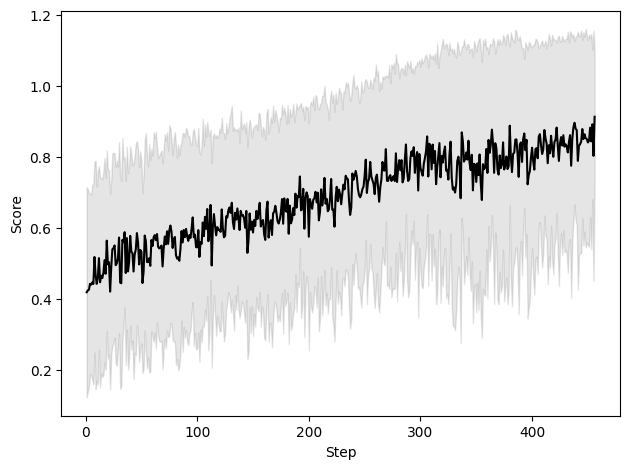

In [57]:
plot("data/6Y5F_stage_nim_1_luxor.csv", "Score", "Score", "results/RL_score_vs_step.png")

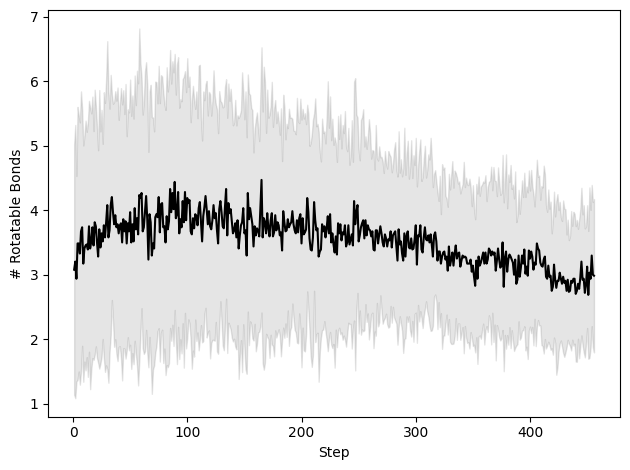

In [58]:
plot("data/6Y5F_stage_nim_1_luxor.csv", "# rotatable bonds (<7) (raw)", "# Rotatable Bonds", "results/RL_nRot_vs_step.png")

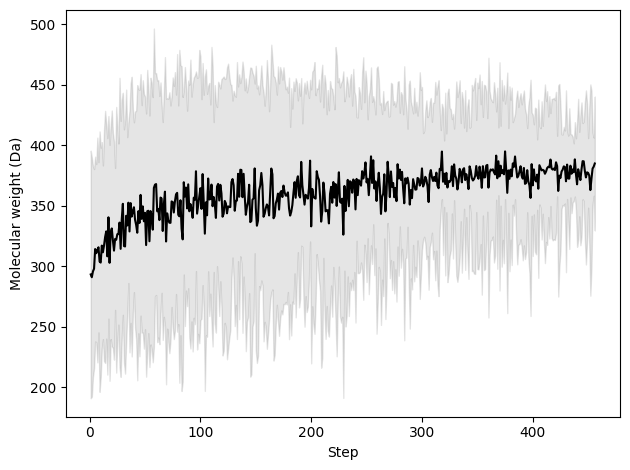

In [59]:
plot("data/6Y5F_stage_nim_1_luxor.csv", "Molecular weight (300-450) (raw)", "Molecular weight (Da)", "results/RL_MW_vs_step.png")

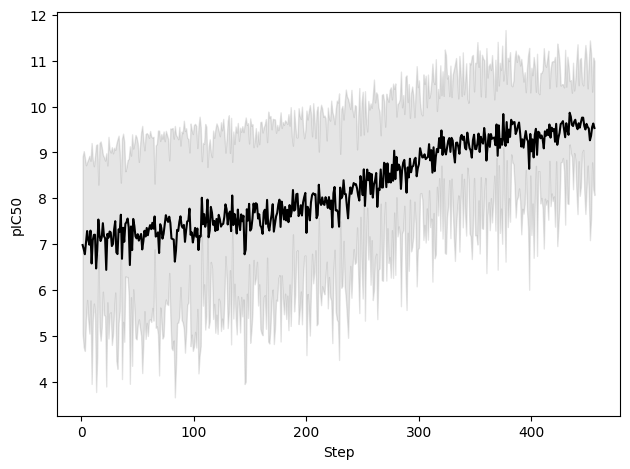

In [60]:
plot("data/6Y5F_stage_nim_1_luxor.csv", "NIM Boltz-2 (raw)", "pIC50", "results/RL_affinity_vs_step.png")

### Molecules

In [61]:
pIC50 = 9
MW = 500
nRot = 7

In [62]:
# Unique generated compounds over pIC50
RL1 = pd.read_csv("data/6Y5F_stage_nim_1_flamingo.csv") 
RL2 = pd.read_csv("data/6Y5F_stage_nim_1_flamingo_noInception.csv")
RL3 = pd.read_csv("data/6Y5F_stage_nim_1_luxor.csv")

reinvent = pd.concat([RL1, RL2, RL3], ignore_index=True).sort_values("NIM Boltz-2 (raw)", ascending=False).reset_index(drop=True)
reinvent = reinvent[["Maize ID (NIM Boltz-2)", "NIM Boltz-2 (raw)", "Molecular weight (300-450) (raw)", "# rotatable bonds (<7) (raw)", "SMILES"]].drop_duplicates("Maize ID (NIM Boltz-2)")

#reinvent = reinvent[reinvent["Molecular weight (300-450) (raw)"] < MW]
#reinvent = reinvent[reinvent["# rotatable bonds (<7) (raw)"] <= nRot]
reinvent = reinvent[reinvent["NIM Boltz-2 (raw)"] >= pIC50]

filename = f"results/reinvent_stage_nim_pIC50_{pIC50}"
reinvent.to_csv(f"{filename}.csv", index=False)
reinvent[["SMILES", "Maize ID (NIM Boltz-2)"]].to_csv(f"{filename}.smi", index=False, header=False, sep="\t")
reinvent

,Maize ID (NIM Boltz-2),NIM Boltz-2 (raw),Molecular weight (300-450) (raw),# rotatable bonds (<7) (raw),SMILES
0,MKGRVUBAZOXECG-MPIMZMORNA-N,11.3809,373.363,2.0,Nc1c(F)c(N2CC(N)C2)cc2c1c(=O)c1c(=O)[nH]cc(F)c...
25,VYJPXGGFSIBLJH-CNDWOTARNA-N,11.2104,403.437,2.0,CC1CN(c2c(F)c(N)c3c(=O)c4[nH]c(=N)[nH]c4n(C4CC...
26,KFRLUJUSNVDOBC-IJIQVFRLNA-N,11.1678,386.431,2.0,Nc1c(F)c(N2CCCCC(N)C2)cc2c1c(=O)c1c(=O)[nH][nH...
28,USXBCYBMZGIEBN-JVUVZRCBNA-N,11.1464,436.488,2.0,Nc1c(F)c(N2CC(N)CCC(N)C2)c(F)c2c1c(=O)c1c(=O)[...
29,FXSUDTGUOMBYKC-ASQFFMACNA-N,11.0399,433.434,4.0,NCCC1CCN(c2c(F)c(N)c3c(=O)c4c(=O)[nH]cc(F)c4n(...
...,...,...,...,...,...
11704,VKWOLQDPHMDGMM-UHFFFAOYNA-N,9.0045,413.428,7.0,O=c1n(Cc2nc3cc(F)c(F)cc3n2CCCCO)c2cnccc2n1C1CC1
11705,WVQJXMDSWLBRPA-IHHFKLPMNA-N,9.0045,312.417,5.0,CN1CCCC1CCNC(=O)c1n[nH]c2ccc(C3CC3)cc12
11706,CLXAYSYYPPYQPI-FGZAEZAUNA-N,9.0045,360.360,5.0,O=C1NCC(CCc2ccccc2)N(Cc2cc(F)c(O)c(F)c2)C1=O
11707,YOEOAHVDUJEPSD-NRASODHHNA-N,9.0045,378.379,3.0,NC1CCCCN(c2nc(F)c3c(=O)c(C(=O)O)cn(C4CC4)c3c2F)C1
